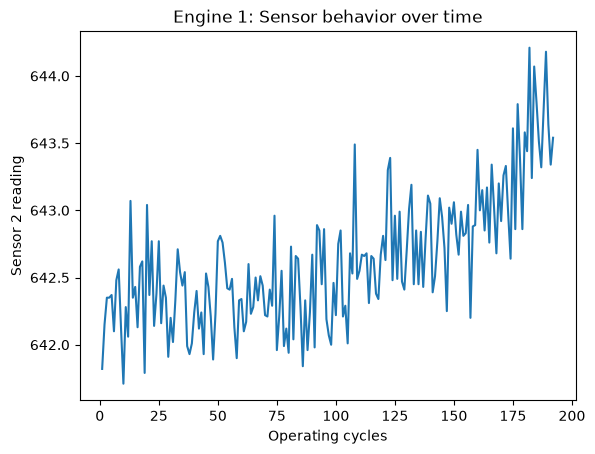

In [7]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

# Load our curated FD001 training dataset.
df = pd.read_parquet("../data/curated/train/train_FD001.parquet")

# Examine the first five records.
# df.head(5)
# df.info()
# Count unique engines and examine their operating lifetimes.
# print("Engines:", df["unit_number"].nunique())
# print(df.groupby("unit_number")["time_in_cycles"].max().describe())

# Identify sensors with little or no variation.
sensors = [col for col in df.columns if col.startswith("sensor_measurement")]
df[sensors].std().sort_values()


# Examine how one sensor changes as an engine approaches failure.
engine = df[df["unit_number"] == 1]
plt.plot(engine["time_in_cycles"], engine["sensor_measurement2"])
plt.xlabel("Operating cycles")
plt.ylabel("Sensor 2 reading")
plt.title("Engine 1: Sensor behavior over time")
plt.show()

In [8]:
# Identify sensors with little or no variation.
sensors = [col for col in df.columns if col.startswith("sensor_measurement")]
df[sensors].std().sort_values()

sensor_measurement1     0.000000e+00
sensor_measurement10    0.000000e+00
sensor_measurement19    0.000000e+00
sensor_measurement18    0.000000e+00
sensor_measurement16    3.469531e-18
sensor_measurement5     5.329200e-15
sensor_measurement6     1.388985e-03
sensor_measurement15    3.750504e-02
sensor_measurement8     7.098548e-02
sensor_measurement13    7.191892e-02
sensor_measurement21    1.082509e-01
sensor_measurement20    1.807464e-01
sensor_measurement11    2.670874e-01
sensor_measurement2     5.000533e-01
sensor_measurement12    7.375534e-01
sensor_measurement7     8.850923e-01
sensor_measurement17    1.548763e+00
sensor_measurement3     6.131150e+00
sensor_measurement4     9.000605e+00
sensor_measurement14    1.907618e+01
sensor_measurement9     2.208288e+01
dtype: float64

In [11]:
df[sensors + ["RUL"]].corr()["RUL"].drop("RUL").sort_values()

sensor_measurement11   -0.696228
sensor_measurement4    -0.678948
sensor_measurement15   -0.642667
sensor_measurement2    -0.606484
sensor_measurement17   -0.606154
sensor_measurement3    -0.584520
sensor_measurement8    -0.563968
sensor_measurement13   -0.562569
sensor_measurement9    -0.390102
sensor_measurement14   -0.306769
sensor_measurement6    -0.128348
sensor_measurement20    0.629428
sensor_measurement21    0.635662
sensor_measurement7     0.657223
sensor_measurement12    0.671983
sensor_measurement1          NaN
sensor_measurement5          NaN
sensor_measurement10         NaN
sensor_measurement16         NaN
sensor_measurement18         NaN
sensor_measurement19         NaN
Name: RUL, dtype: float64